In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load Dataset
df = pd.read_csv("iris.csv")

print("Original Dataset:")
display(df.head())

print("Dataset Information:")
df.info()

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Original Dataset:


,sepal.length,sepal.width,petal.length,petal.width,species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
Missing Values:
sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
species         0
dtype: int64
Duplicate Rows: 1


In [5]:
# Data Cleaning
df.columns = df.columns.str.strip()

cols = []

for c in df.columns:
    if "sepal" in c.lower() or "petal" in c.lower():
        cols.append(c)

df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")

df = df.drop_duplicates()
df[cols] = df[cols].fillna(df[cols].mean())
df = df.dropna()

print("Cleaned Dataset:")
display(df.head())

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("Statistical Summary:")
display(df.describe())

Cleaned Dataset:


,sepal.length,sepal.width,petal.length,petal.width,species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Missing Values After Cleaning:
sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
species         0
dtype: int64
Statistical Summary:


,sepal.length,sepal.width,petal.length,petal.width
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Correlation Matrix:


,sepal.length,sepal.width,petal.length,petal.width
sepal.length,1.000000,-0.118129,0.873738,0.820620
sepal.width,-0.118129,1.000000,-0.426028,-0.362894
petal.length,0.873738,-0.426028,1.000000,0.962772
petal.width,0.820620,-0.362894,0.962772,1.000000


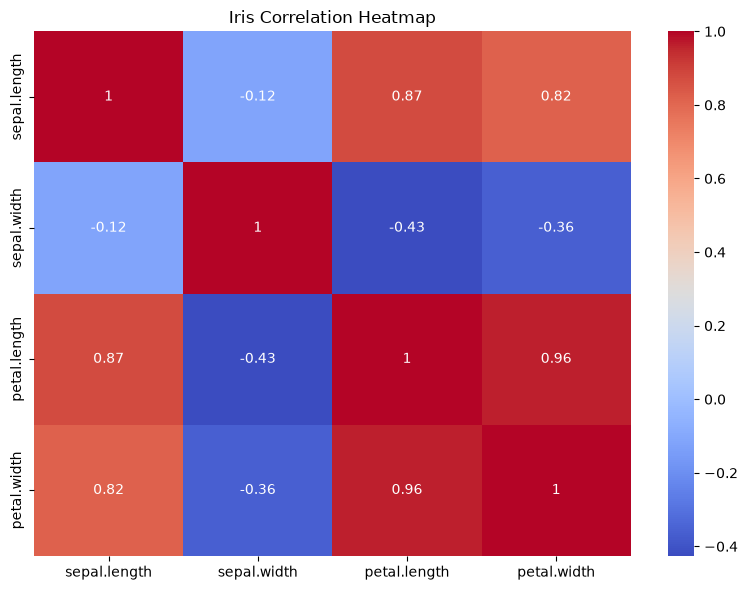

In [4]:
# Correlation Matrix
corr = df[cols].corr()

print("Correlation Matrix:")
display(corr)

# Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Iris Correlation Heatmap")
plt.tight_layout()
plt.show()